# Cognifyz Technologies - Data Science Internship
## Level 1 | Task 1: Data Exploration & Preprocessing | Task 2: Descriptive Analysis | Task 3: Geospatial Analysis
Dataset: `Dataset_.csv` (restaurant data)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# Dataset_.csv must be in the same folder as this notebook
df = pd.read_csv("Dataset .csv", encoding="latin-1")
df.columns = df.columns.str.replace("ï»¿", "", regex=False).str.strip()  # remove BOM from first column name
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


# Task 1: Data Exploration and Preprocessing
### 1.1 Number of rows and columns

In [2]:
rows, cols = df.shape
print(f"Rows: {rows}\nColumns: {cols}")
df.info()

Rows: 9551
Columns: 21
<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   str    
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   str    
 4   Address               9551 non-null   str    
 5   Locality              9551 non-null   str    
 6   Locality Verbose      9551 non-null   str    
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   str    
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   str    
 12  Has Table booking     9551 non-null   str    
 13  Has Online delivery   9551 non-null   str    
 14  Is delivering now     9551 non-null   str    
 15  Switch to

### 1.2 Missing values in each column

In [3]:
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() else "No missing values")
print("\nTotal missing:", missing.sum())

Cuisines    9
dtype: int64

Total missing: 9


Only **Cuisines** has missing values (9 rows). Since it is a categorical column and a tiny share of the data (~0.09%), I fill it with `'Unknown'` instead of dropping rows.

In [4]:
df["Cuisines"] = df["Cuisines"].fillna("Unknown")
print("Missing values after handling:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values after handling: 0
Duplicate rows: 0


### 1.3 Data type conversion

In [5]:
print(df.dtypes)

Restaurant ID             int64
Restaurant Name             str
Country Code              int64
City                        str
Address                     str
Locality                    str
Locality Verbose            str
Longitude               float64
Latitude                float64
Cuisines                    str
Average Cost for two      int64
Currency                    str
Has Table booking           str
Has Online delivery         str
Is delivering now           str
Switch to order menu        str
Price range               int64
Aggregate rating        float64
Rating color                str
Rating text                 str
Votes                     int64
dtype: object


In [6]:
# IDs and country code are identifiers/categories, not quantities -> convert to category/string
df["Restaurant ID"] = df["Restaurant ID"].astype(str)
df["Country Code"] = df["Country Code"].astype("category")
df["Price range"] = df["Price range"].astype("category")   # ordered category 1-4
for c in ["Has Table booking", "Has Online delivery", "Is delivering now", "Switch to order menu",
          "City", "Currency", "Rating color", "Rating text"]:
    df[c] = df[c].astype("category")
df.dtypes

Restaurant ID                str
Restaurant Name              str
Country Code            category
City                    category
Address                      str
Locality                     str
Locality Verbose             str
Longitude                float64
Latitude                 float64
Cuisines                     str
Average Cost for two       int64
Currency                category
Has Table booking       category
Has Online delivery     category
Is delivering now       category
Switch to order menu    category
Price range             category
Aggregate rating         float64
Rating color            category
Rating text             category
Votes                      int64
dtype: object

### 1.4 Distribution of target variable - Aggregate rating & class imbalance

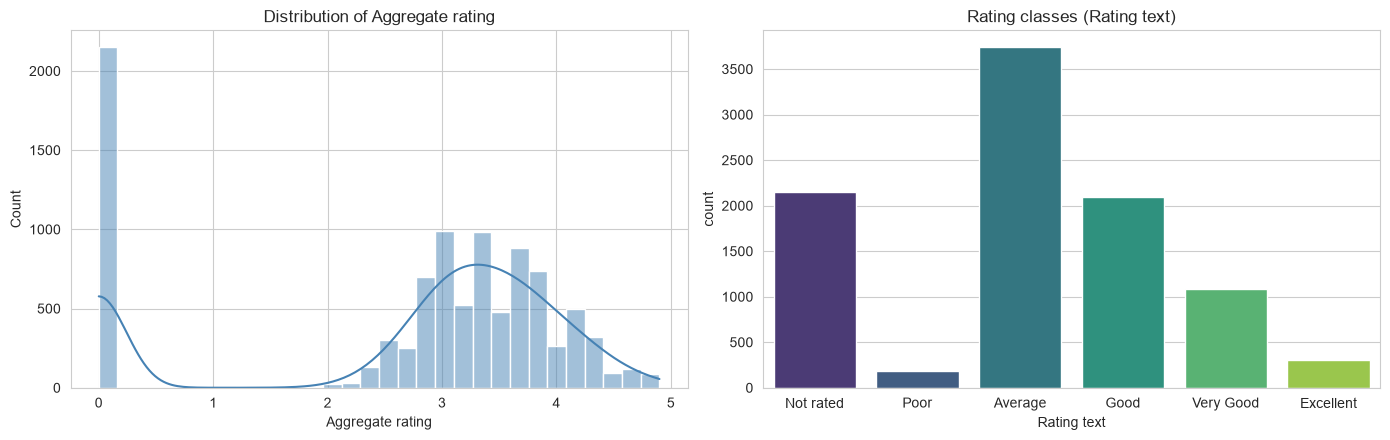

             Count  Percentage
Rating text                   
Not rated     2148       22.49
Poor           186        1.95
Average       3737       39.13
Good          2100       21.99
Very Good     1079       11.30
Excellent      301        3.15

Zero ratings (not rated): 2148
Imbalance ratio (largest / smallest class): 20.1


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df["Aggregate rating"], bins=30, kde=True, color="steelblue", ax=ax[0])
ax[0].set_title("Distribution of Aggregate rating")
order = ["Not rated", "Poor", "Average", "Good", "Very Good", "Excellent"]
sns.countplot(data=df, x="Rating text", order=order, palette="viridis", ax=ax[1])
ax[1].set_title("Rating classes (Rating text)")
plt.tight_layout(); plt.show()

counts = df["Rating text"].value_counts().reindex(order)
pct = (counts / len(df) * 100).round(2)
print(pd.DataFrame({"Count": counts, "Percentage": pct}))
print("\nZero ratings (not rated):", (df["Aggregate rating"] == 0).sum())
print("Imbalance ratio (largest / smallest class):", round(counts.max() / counts.min(), 1))

**Observation:** The target is clearly **imbalanced**. Most restaurants fall in *Average* (~39%), *Not rated* (~22.5%, rating = 0) and *Good* (~22%), while *Excellent* and *Poor* are very rare (~3% and ~2%). The large spike at 0 consists of unrated restaurants - they should be treated carefully (or removed) before modelling.

# Task 2: Descriptive Analysis
### 2.1 Basic statistical measures for numerical columns

In [8]:
num_cols = ["Longitude", "Latitude", "Average Cost for two", "Aggregate rating", "Votes"]
stats = df[num_cols].agg(["count", "mean", "median", "std", "min", "max"]).T
stats["skew"] = df[num_cols].skew()
stats.round(3)

,count,mean,median,std,min,max,skew
Longitude,9551.0,64.127,77.192,41.467,-157.948,174.832,-2.807
Latitude,9551.0,25.854,28.570,11.008,-41.330,55.977,-3.082
Average Cost for two,9551.0,1199.211,400.000,16121.183,0.000,800000.000,35.478
Aggregate rating,9551.0,2.666,3.200,1.516,0.000,4.900,-0.954
Votes,9551.0,156.910,31.000,430.169,0.000,10934.000,8.808


### 2.2 Distribution of categorical variables - Country Code, City, Cuisines

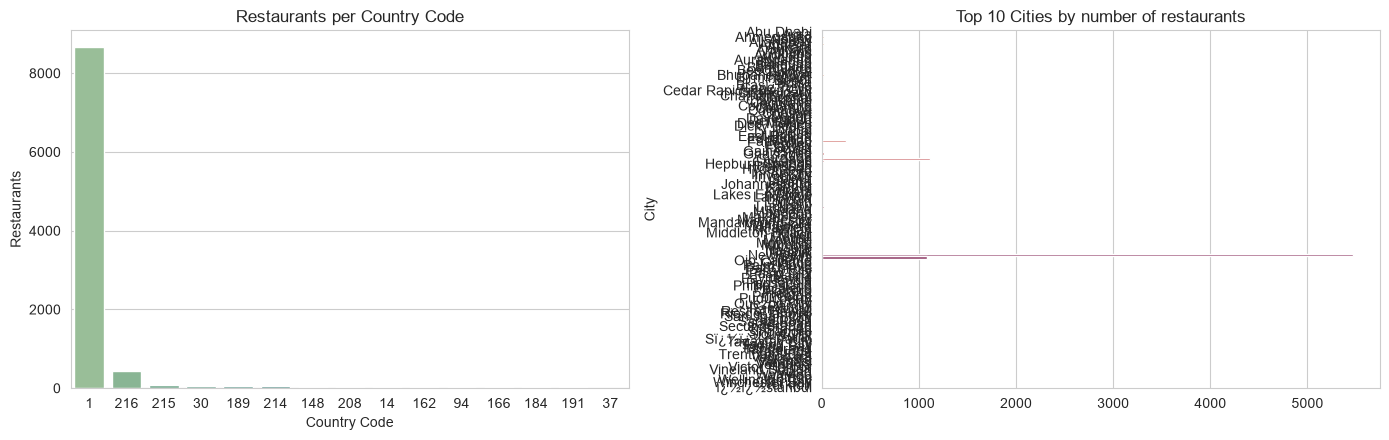

              Restaurants  Percentage
Country Code                         
1                    8652       90.59
216                   434        4.54
215                    80        0.84
30                     60        0.63
189                    60        0.63
214                    60        0.63
148                    40        0.42
208                    34        0.36
14                     24        0.25
162                    22        0.23
94                     21        0.22
166                    20        0.21
184                    20        0.21
191                    20        0.21
37                      4        0.04


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
cc = df["Country Code"].value_counts()
sns.barplot(x=cc.index.astype(str), y=cc.values, palette="crest", ax=ax[0])
ax[0].set_title("Restaurants per Country Code"); ax[0].set_xlabel("Country Code"); ax[0].set_ylabel("Restaurants")
top_city = df["City"].value_counts().head(10)
sns.barplot(x=top_city.values, y=top_city.index, palette="flare", ax=ax[1])
ax[1].set_title("Top 10 Cities by number of restaurants")
plt.tight_layout(); plt.show()
print(cc.to_frame("Restaurants").assign(Percentage=(cc / len(df) * 100).round(2)))

### 2.3 Top cuisines and cities with the highest number of restaurants

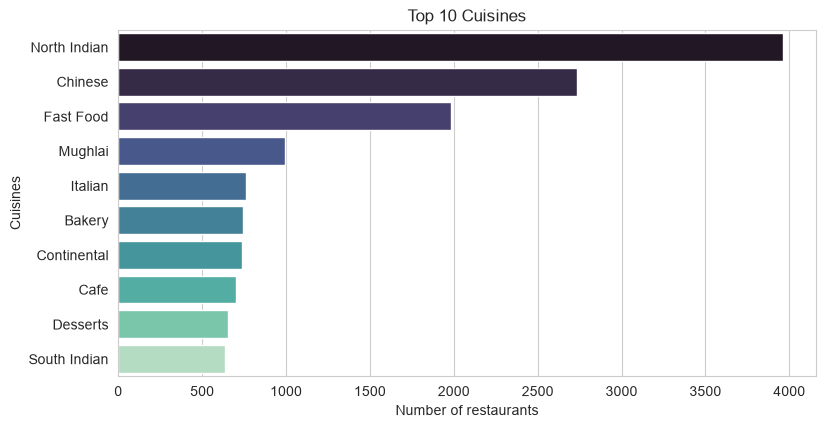

Top 10 cuisines:
 Cuisines
North Indian    3960
Chinese         2735
Fast Food       1986
Mughlai          995
Italian          764
Bakery           745
Continental      736
Cafe             703
Desserts         653
South Indian     636
Name: count, dtype: int64 

Top 10 cities:
 City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Ahmedabad         21
Amritsar          21
Bhubaneshwar      21
Guwahati          21
Lucknow           21
Name: count, dtype: int64


In [10]:
# A restaurant can list several cuisines ("French, Japanese, Desserts") -> split and count each one
cuisine_counts = (df["Cuisines"].str.split(",").explode().str.strip().value_counts())
cuisine_counts = cuisine_counts.drop("Unknown", errors="ignore")
top_cuisines = cuisine_counts.head(10)

plt.figure(figsize=(9, 4.5))
sns.barplot(x=top_cuisines.values, y=top_cuisines.index, palette="mako")
plt.title("Top 10 Cuisines"); plt.xlabel("Number of restaurants"); plt.show()

print("Top 10 cuisines:\n", top_cuisines, "\n")
print("Top 10 cities:\n", df["City"].value_counts().head(10))

**Observation:** North Indian is the most common cuisine, followed by Chinese and Fast Food. New Delhi has by far the most restaurants, followed by Gurgaon, Noida and Faridabad - the dataset is heavily India-centric.

# Task 3: Geospatial Analysis
### 3.1 Visualize restaurant locations using latitude & longitude

Valid coordinates: 9052 of 9551


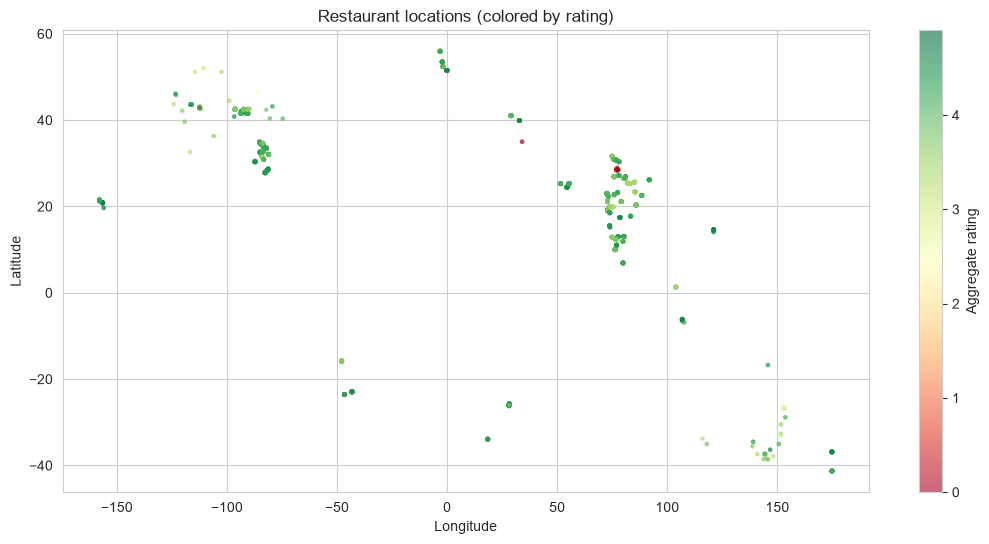

In [11]:
geo = df[(df["Latitude"] != 0) & (df["Longitude"] != 0)]   # drop invalid (0, 0) coordinates
print("Valid coordinates:", len(geo), "of", len(df))

plt.figure(figsize=(13, 6))
sc = plt.scatter(geo["Longitude"], geo["Latitude"], c=geo["Aggregate rating"], cmap="RdYlGn", s=6, alpha=0.6)
plt.colorbar(sc, label="Aggregate rating")
plt.title("Restaurant locations (colored by rating)")
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.show()

*(Optional - interactive map)* If you have `folium` installed (`pip install folium`), run the next cell for a zoomable map.

In [12]:
try:
    import folium
    from folium.plugins import MarkerCluster
    m = folium.Map(location=[geo["Latitude"].median(), geo["Longitude"].median()], zoom_start=4)
    cluster = MarkerCluster().add_to(m)
    for _, r in geo.sample(1500, random_state=42).iterrows():
        folium.CircleMarker([r["Latitude"], r["Longitude"]], radius=3,
                            popup=f'{r["Restaurant Name"]} ({r["Aggregate rating"]})').add_to(cluster)
    m
except ImportError:
    print("folium not installed - skipping interactive map")

folium not installed - skipping interactive map


### 3.2 Distribution of restaurants across cities and countries

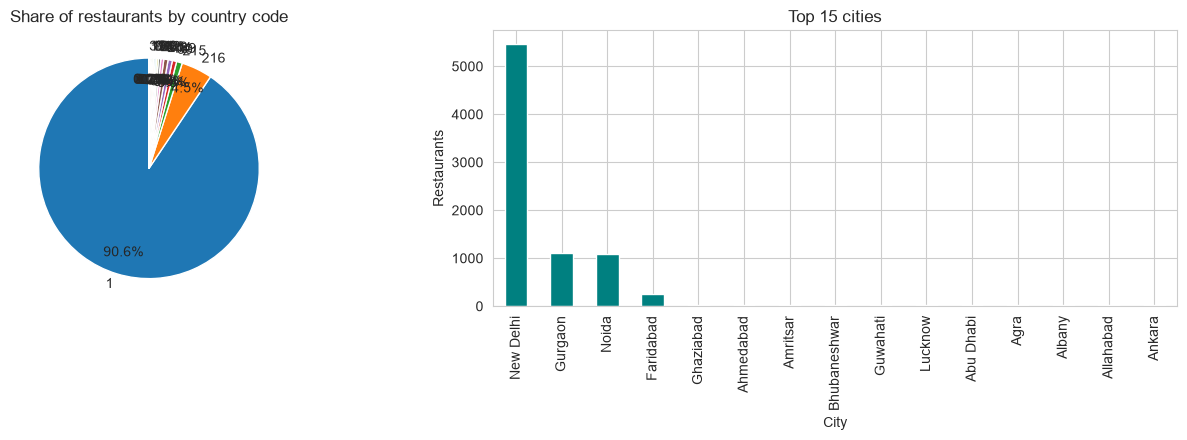

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
df["Country Code"].value_counts().plot.pie(autopct="%1.1f%%", ax=ax[0], startangle=90, pctdistance=0.8)
ax[0].set_ylabel(""); ax[0].set_title("Share of restaurants by country code")
df["City"].value_counts().head(15).plot.bar(ax=ax[1], color="teal")
ax[1].set_title("Top 15 cities"); ax[1].set_ylabel("Restaurants")
plt.tight_layout(); plt.show()

### 3.3 Correlation between location and rating

Correlation with Aggregate rating:
Latitude           -0.124
Longitude          -0.206
Aggregate rating    1.000
Name: Aggregate rating, dtype: float64

Top 5 cities by average rating (>= 20 rated restaurants):
                 mean  count
City                       
London          4.54     20
Orlando         4.47     20
Tampa Bay       4.41     20
Rest of Hawaii  4.41     20
Bangalore       4.38     20

Bottom 5 cities:
            mean  count
City                  
Gurgaon    3.33    874
New Delhi  3.30   3975
Noida      3.16    676
Faridabad  3.10    147
Ghaziabad  3.10     23


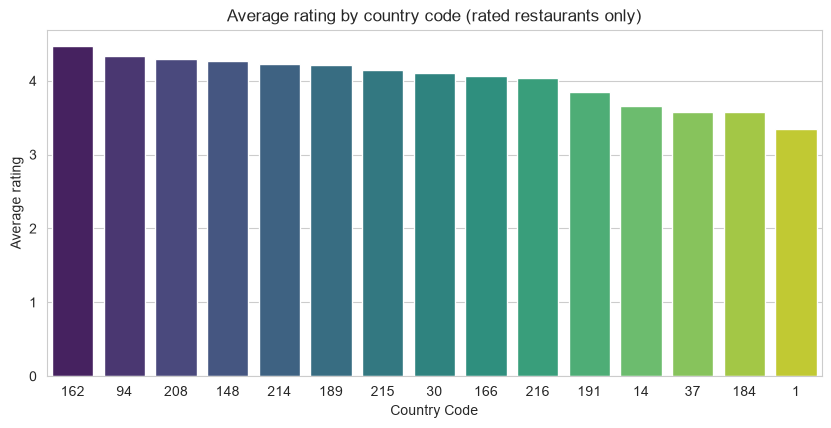

In [14]:
print("Correlation with Aggregate rating:")
print(geo[["Latitude", "Longitude", "Aggregate rating"]].corr()["Aggregate rating"].round(3))

rated = geo[geo["Aggregate rating"] > 0]
city_stats = (rated.groupby("City")["Aggregate rating"].agg(["mean", "count"])
              .query("count >= 20").sort_values("mean", ascending=False))
print("\nTop 5 cities by average rating (>= 20 rated restaurants):\n", city_stats.head(5).round(2))
print("\nBottom 5 cities:\n", city_stats.tail(5).round(2))

plt.figure(figsize=(10, 4.5))
country_avg = rated.groupby("Country Code")["Aggregate rating"].mean().sort_values(ascending=False)
sns.barplot(x=country_avg.index.astype(str), y=country_avg.values, palette="viridis")
plt.title("Average rating by country code (rated restaurants only)"); plt.ylabel("Average rating"); plt.show()

**Conclusion:** Latitude/longitude alone show only a **weak linear correlation** with rating, because the data is clustered in a few regions (mostly India). However, location still matters through the *city/country* - averages differ clearly between cities and countries, so `City`/`Country Code` are more useful predictors than raw coordinates.